# Core ML Concepts Demo — California Housing Dataset

This notebook uses the **real California Housing dataset** (from sklearn, US Census 1990) to demonstrate the comparisons:

1. Baseline Linear Regression and Decision Tree models
2. Underfitting
3. Overfitting
4. Bias–Variance Tradeoff
5. Data Leakage
6. Feature Scaling (including a scale-SENSITIVE model, so the difference is unmistakable)
7. Feature Selection (with deliberately injected noise features, so selection is unmistakable)
8. Cross-Validation — 5-Fold CV vs a single "standard" train/validation split

Only **Linear Regression** and **Decision Tree Regression** are used as the core baseline models. One additional model, **SGDRegressor** (gradient-based Linear Regression), is used *only* in the Feature Scaling section, because ordinary `LinearRegression` and `DecisionTreeRegressor` are both naturally insensitive to feature scale — using them alone would make the scaling lesson invisible.

The main metric throughout is **Mean Squared Error (MSE)**. The final section also reports **RMSE** and **MAE**.

### Important evaluation rule

The final test set is kept **completely untouched** during model selection, tuning, scaling, and feature selection.

We use **training data + cross-validation** for every comparison and decision. The final test set is used **once**, at the very end, only for the final evaluation.


## Setup

In [ ]:
# Import NumPy for numerical operations and reproducible random data.
import numpy as np

# Import Pandas for working with the dataset.
import pandas as pd

# Import Matplotlib for plots.
import matplotlib.pyplot as plt

# Real dataset (US Census 1990, California Housing).
from sklearn.datasets import fetch_california_housing

# Split data into training and final test sets, plus CV tools.
from sklearn.model_selection import train_test_split, KFold, cross_val_score

# Models used in this notebook.
from sklearn.linear_model import LinearRegression, SGDRegressor

from sklearn.tree import DecisionTreeRegressor

# Feature preprocessing and feature selection.
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.pipeline import Pipeline

# Evaluation metrics.
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Make all random operations reproducible.
np.random.seed(42)

# Use a consistent plot size.
plt.rcParams['figure.figsize'] = (7, 4)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

print("Setup complete.")


Setup complete.


## 1. Load the Dataset — California Housing

This is **real data**, not synthetic: 20,640 census block groups from the 1990 California census.

**Features:**

| Feature | Meaning |
|---|---|
| `MedInc` | Median income in the block group (10,000s of USD) |
| `HouseAge` | Median house age in the block group (years) |
| `AveRooms` | Average number of rooms per household |
| `AveBedrms` | Average number of bedrooms per household |
| `Population` | Block group population |
| `AveOccup` | Average number of household members |
| `Latitude` | Block group latitude |
| `Longitude` | Block group longitude |

**Target:** `MedHouseVal` — median house value for the block group (in $100,000s).

> Notice the features are on **very different natural scales** — `Population` can be in the thousands, while `MedInc` is a small number like 3–8, and `Latitude`/`Longitude` are around 32–42 / −124 to −114. This real scale difference is exactly what makes the Feature Scaling section meaningful later.

### Injected noise features

To make **Feature Selection** clearly demonstrable, we deliberately add two **pure random noise** columns to this real dataset. These carry no real signal about house prices at all. A good feature selection method should identify and discard them.


In [ ]:
# Fetch the real California Housing dataset.
housing = fetch_california_housing(as_frame=True)

df = housing.frame.copy()

# Rename target for clarity.
df = df.rename(columns={'MedHouseVal': 'price'})

# ── Inject two pure-noise features (deliberately uninformative) ──
# These are pure random numbers, completely unrelated to house prices.
# A good feature selection method should identify these as useless.
df['noise_1'] = np.random.randn(len(df))
df['noise_2'] = np.random.randn(len(df))

print("REAL DATASET: California Housing (1990 US Census)")
print(f"  Samples : {len(df)}")
print(f"  Features: {df.shape[1] - 1} (8 real + 2 injected noise columns)")
print(f"  Target  : price (median house value, $100,000s)")
print()
print(df.describe().round(2))


REAL DATASET: California Housing (1990 US Census)
  Samples : 20640
  Features: 10 (8 real + 2 injected noise columns)
  Target  : price (median house value, $100,000s)

         MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  \
count  20640.00  20640.00  20640.00   20640.00    20640.00  20640.00   
mean       3.87     28.64      5.43       1.10     1425.48      3.07   
std        1.90     12.59      2.47       0.47     1132.46     10.39   
min        0.50      1.00      0.85       0.33        3.00      0.69   
25%        2.56     18.00      4.44       1.01      787.00      2.43   
50%        3.53     29.00      5.23       1.05     1166.00      2.82   
75%        4.74     37.00      6.05       1.10     1725.00      3.28   
max       15.00     52.00    141.91      34.07    35682.00   1243.33   

       Latitude  Longitude     price   noise_1   noise_2  
count  20640.00   20640.00  20640.00  20640.00  20640.00  
mean      35.63    -119.57      2.07      0.00     -0.01  
std 

In [ ]:
# Notice how different the natural SCALES of these features are.
print("Feature ranges (this is why scaling matters):")
print()
feature_cols = [c for c in df.columns if c != 'price']
for col in feature_cols:
    print(f"  {col:<12} min={df[col].min():>10.2f}   max={df[col].max():>12.2f}")


Feature ranges (this is why scaling matters):

  MedInc       min=      0.50   max=       15.00
  HouseAge     min=      1.00   max=       52.00
  AveRooms     min=      0.85   max=      141.91
  AveBedrms    min=      0.33   max=       34.07
  Population   min=      3.00   max=    35682.00
  AveOccup     min=      0.69   max=     1243.33
  Latitude     min=     32.54   max=       41.95
  Longitude    min=   -124.35   max=     -114.31
  noise_1      min=     -3.92   max=        4.48
  noise_2      min=     -4.47   max=        3.73


## 2. Train/Test Split

We lock away 25% of the real data as the final test set **right now**


In [ ]:
# Separate input features from the target.
X = df.drop(columns=['price'])
y = df['price']

# Keep 25% aside as the final test set.
# The test set will not be used for model selection, scaling, or feature selection.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

print("Train shape:", X_train.shape)
print("Test shape :", X_test.shape)
print()
print("From this point on, X_test / y_test are LOCKED until Section 11.")


Train shape: (15480, 10)
Test shape : (5160, 10)

From this point on, X_test / y_test are LOCKED until Section 11.


## 3. Baseline Models — Linear Regression vs Decision Tree

We fit two baseline models on the real training data and compare **Train MSE** vs **5-Fold CV MSE**.

This first comparison already previews the whole notebook's theme: **Train MSE is always optimistic. CV MSE is a more honest estimate of real-world performance.**


In [ ]:
# A simple Linear Regression baseline.
lin_baseline = LinearRegression()
lin_baseline.fit(X_train, y_train)

# An unrestricted Decision Tree.
# max_depth=None allows the tree to keep splitting until its stopping rules are met.
tree_baseline = DecisionTreeRegressor(
    max_depth=None,
    random_state=42
)
tree_baseline.fit(X_train, y_train)

# Use the same 5 folds everywhere in this notebook for consistency.
kf = KFold(n_splits=5, shuffle=True, random_state=42)

def cv_mse(model, X_data, y_data, cv=None):
    # cross_val_score returns negative MSE because sklearn uses
    # "higher score is better" for all scoring functions (this is only for coding using sklearn - our understading of MSE stands the same)
    negative_mse = cross_val_score(
        model,
        X_data,
        y_data,
        cv=cv if cv is not None else kf,
        scoring='neg_mean_squared_error'
    )
    # Convert back to the usual positive MSE.
    return -negative_mse

def report_development_performance(model, name):
    # Training MSE: how well the fitted model matches training examples.
    train_mse = mean_squared_error(y_train, model.predict(X_train))

    # CV MSE: average validation performance using only training data.
    fold_mse = cv_mse(model, X_train, y_train)

    print(name)
    print(f"  Train MSE   : {train_mse:.4f}")
    print(f"  Mean CV MSE : {fold_mse.mean():.4f}")
    print(f"  CV MSE SD   : {fold_mse.std():.4f}")
    return train_mse, fold_mse

baseline_lin_train, baseline_lin_cv = report_development_performance(
    lin_baseline, "Linear Regression"
)
print()
baseline_tree_train, baseline_tree_cv = report_development_performance(
    tree_baseline, "Decision Tree"
)

print()
print("--> Notice: the unrestricted tree's Train MSE is near ZERO")



Linear Regression
  Train MSE   : 0.5205
  Mean CV MSE : 0.5224
  CV MSE SD   : 0.0211

Decision Tree
  Train MSE   : 0.0000
  Mean CV MSE : 0.5701
  CV MSE SD   : 0.0125

--> Notice: the unrestricted tree's Train MSE is near ZERO


## 4. Underfitting

We intentionally cripple the model two ways on the **real data**:

1. Linear Regression using only **ONE weak feature** (`AveRooms`, which barely relates to price)
2. A Decision Tree limited to **`max_depth=1`** (a single split — the simplest possible tree)

Both should show **high error on training data AND high error on CV** — the signature of underfitting.


In [ ]:
# ── Underfit #1: Linear Regression with a weak single feature ──
X_train_1f = X_train[['AveRooms']]

underfit_lr = LinearRegression()
underfit_lr.fit(X_train_1f, y_train)

train_mse_u = mean_squared_error(y_train, underfit_lr.predict(X_train_1f))
underfit_lr_cv = cv_mse(LinearRegression(), X_train_1f, y_train)

print("Underfit Linear Regression (AveRooms only)")
print(f"  Train MSE   : {train_mse_u:.4f}")
print(f"  Mean CV MSE : {underfit_lr_cv.mean():.4f}")
print(f"  CV MSE SD   : {underfit_lr_cv.std():.4f}")
print()

# ── Underfit #2: Decision Tree with max_depth=1 (a single split) ──
underfit_tree = DecisionTreeRegressor(max_depth=1, random_state=42)
underfit_tree.fit(X_train, y_train)

train_mse_ut = mean_squared_error(y_train, underfit_tree.predict(X_train))
underfit_tree_cv = cv_mse(DecisionTreeRegressor(max_depth=1, random_state=42), X_train, y_train)

print("Underfit Decision Tree (max_depth=1)")
print(f"  Train MSE   : {train_mse_ut:.4f}")
print(f"  Mean CV MSE : {underfit_tree_cv.mean():.4f}")
print(f"  CV MSE SD   : {underfit_tree_cv.std():.4f}")
print()

print("--> Compare with the FULL baseline models from Section 3:")
print(f"    Full Linear Regression  Train MSE = {baseline_lin_train:.4f}")
print(f"    Full Decision Tree      Train MSE = {baseline_tree_train:.4f}")
print()
print("--> Both underfit models are WORSE on train AND CV than the full baseline.")
print("    High error EVERYWHERE (train and CV) is the sign of underfitting.")


Underfit Linear Regression (AveRooms only)
  Train MSE   : 1.3015
  Mean CV MSE : 1.3058
  CV MSE SD   : 0.0452

Underfit Decision Tree (max_depth=1)
  Train MSE   : 0.9135
  Mean CV MSE : 0.9183
  CV MSE SD   : 0.0241

--> Compare with the FULL baseline models from Section 3:
    Full Linear Regression  Train MSE = 0.5205
    Full Decision Tree      Train MSE = 0.0000

--> Both underfit models are WORSE on train AND CV than the full baseline.
    High error EVERYWHERE (train and CV) is the sign of underfitting.


## 5. Overfitting

Now the opposite mistake: a Decision Tree with **no depth limit** on the real data. It can keep splitting until almost every training point sits in its own tiny region.

Compare it against a **restricted tree** (`max_depth=6`).


In [ ]:
# Very flexible tree (already fit in Section 3 as tree_baseline, refit here for clarity).
deep_tree = DecisionTreeRegressor(max_depth=None, random_state=42)
deep_tree.fit(X_train, y_train)

# A more restricted, shallower tree.
shallow_tree = DecisionTreeRegressor(max_depth=6, random_state=42)
shallow_tree.fit(X_train, y_train)

deep_train, deep_cv = report_development_performance(deep_tree, "Deep Tree (max_depth=None)")
print()
shallow_train, shallow_cv = report_development_performance(shallow_tree, "Restricted Tree (max_depth=6)")

print()
gap_deep = deep_cv.mean() - deep_train
gap_shallow = shallow_cv.mean() - shallow_train
print(f"Deep tree     : Train={deep_train:.4f}, CV={deep_cv.mean():.4f}, GAP={gap_deep:.4f}")
print(f"Shallow tree  : Train={shallow_train:.4f}, CV={shallow_cv.mean():.4f}, GAP={gap_shallow:.4f}")
print()
print("--> The deep tree's GAP between Train and CV MSE is far larger.")
print("    Near-zero training error + much higher CV error = OVERFITTING.")
print("    The restricted tree has a smaller gap — it generalises better,")
print("    even though its training error is higher.")


Deep Tree (max_depth=None)
  Train MSE   : 0.0000
  Mean CV MSE : 0.5701
  CV MSE SD   : 0.0125

Restricted Tree (max_depth=6)
  Train MSE   : 0.4356
  Mean CV MSE : 0.4845
  CV MSE SD   : 0.0241

Deep tree     : Train=0.0000, CV=0.5701, GAP=0.5701
Shallow tree  : Train=0.4356, CV=0.4845, GAP=0.0489

--> The deep tree's GAP between Train and CV MSE is far larger.
    Near-zero training error + much higher CV error = OVERFITTING.
    The restricted tree has a smaller gap — it generalises better,
    even though its training error is higher.


## 6. Bias–Variance Tradeoff

We sweep Decision Tree depth from 1 to 25 on the real training data and plot **Train MSE** vs **5-Fold CV MSE** at every depth.



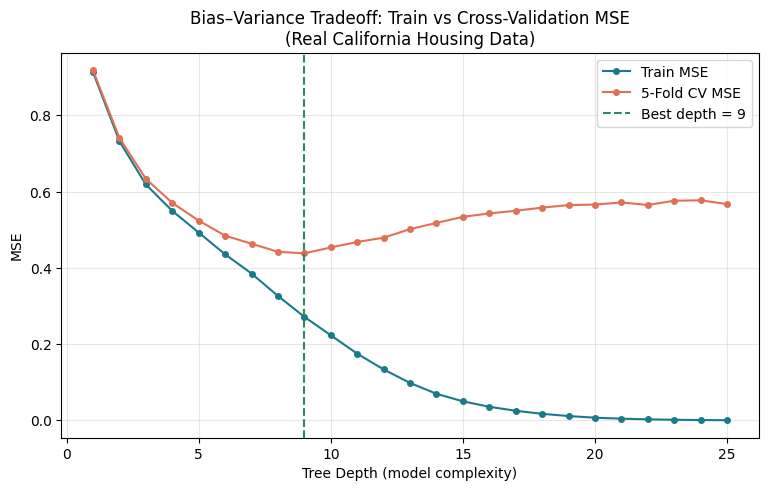

Best depth selected using 5-fold CV: 9
Lowest mean CV MSE: 0.4381

Reading the curve:
  Depth 1-3   : both Train and CV MSE are HIGH and close together  --> UNDERFITTING
  Depth 9      : CV MSE is at its LOWEST point                    --> SWEET SPOT
  Depth 20-25 : Train MSE keeps falling, CV MSE rises again        --> OVERFITTING


In [ ]:
depths = range(1, 26)

train_mses = []
cv_mean_mses = []
cv_std_mses = []

for d in depths:
    model = DecisionTreeRegressor(max_depth=d, random_state=42)
    model.fit(X_train, y_train)

    train_mses.append(mean_squared_error(y_train, model.predict(X_train)))

    fold_mse = cv_mse(DecisionTreeRegressor(max_depth=d, random_state=42), X_train, y_train)
    cv_mean_mses.append(fold_mse.mean())
    cv_std_mses.append(fold_mse.std())

plt.figure(figsize=(9, 5))
plt.plot(list(depths), train_mses, marker='o', markersize=4, label='Train MSE', color='#1A7A8A')
plt.plot(list(depths), cv_mean_mses, marker='o', markersize=4, label='5-Fold CV MSE', color='#E17055')

best_depth = list(depths)[int(np.argmin(cv_mean_mses))]
plt.axvline(x=best_depth, color='#2D8A5E', linestyle='--', linewidth=1.5,
            label=f'Best depth = {best_depth}')

plt.xlabel('Tree Depth (model complexity)')
plt.ylabel('MSE')
plt.title('Bias–Variance Tradeoff: Train vs Cross-Validation MSE\n(Real California Housing Data)')
plt.legend()
plt.show()

print(f"Best depth selected using 5-fold CV: {best_depth}")
print(f"Lowest mean CV MSE: {min(cv_mean_mses):.4f}")
print()
print("Reading the curve:")
print("  Depth 1-3   : both Train and CV MSE are HIGH and close together  --> UNDERFITTING")
print(f"  Depth {best_depth}      : CV MSE is at its LOWEST point                    --> SWEET SPOT")
print("  Depth 20-25 : Train MSE keeps falling, CV MSE rises again        --> OVERFITTING")


## 7. Data Leakage

Two classic leakage mistakes, demonstrated on a **development split carved out of the training data only** (the final test set stays locked).


### 7a. Leakage by Scaling Before Splitting

In [ ]:
# Create a separate leakage-demonstration split from the TRAINING data only.
# This keeps the final test set completely untouched.
X_demo_train, X_demo_val, y_demo_train, y_demo_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=123
)

# WRONG: fit the scaler using both development-train and development-validation data.
scaler_leaky = StandardScaler()
X_demo_all = pd.concat([X_demo_train, X_demo_val])
scaler_leaky.fit(X_demo_all)

X_demo_train_leaky = scaler_leaky.transform(X_demo_train)
X_demo_val_leaky = scaler_leaky.transform(X_demo_val)

leaky_model = LinearRegression()
leaky_model.fit(X_demo_train_leaky, y_demo_train)
leaky_mse = mean_squared_error(y_demo_val, leaky_model.predict(X_demo_val_leaky))

# CORRECT: fit the scaler using development-training data only.
scaler_correct = StandardScaler()
X_demo_train_correct = scaler_correct.fit_transform(X_demo_train)
X_demo_val_correct = scaler_correct.transform(X_demo_val)

correct_model = LinearRegression()
correct_model.fit(X_demo_train_correct, y_demo_train)
correct_mse = mean_squared_error(y_demo_val, correct_model.predict(X_demo_val_correct))

print(f"Validation MSE with LEAKY scaling   : {leaky_mse:.4f}")
print(f"Validation MSE with CORRECT scaling : {correct_mse:.4f}")
print()
print("The values may look similar for ordinary Linear Regression.")
print("The leaky procedure is still INVALID — validation information was used")
print("to compute the scaler's mean/std, contaminating the 'unseen' data assumption.")
print("This mistake becomes much more dangerous with smaller datasets or gradient-based models.")


Validation MSE with LEAKY scaling   : 0.5228
Validation MSE with CORRECT scaling : 0.5228

The values may look similar for ordinary Linear Regression.
The leaky procedure is still INVALID — validation information was used
to compute the scaler's mean/std, contaminating the 'unseen' data assumption.
This mistake becomes much more dangerous with smaller datasets or gradient-based models.


### 7b. Leakage via a Target-Derived Feature

In [ ]:
# Use only the development portion of the data for this leakage demonstration.
df_demo = X_demo_train.copy()
df_demo['price'] = y_demo_train.values

df_demo_val = X_demo_val.copy()
df_demo_val['price'] = y_demo_val.values

# Create a feature DERIVED FROM THE TARGET — classic, dangerous leakage.
# "income_per_price" directly encodes the answer we are trying to predict.
df_demo['income_per_price'] = df_demo['MedInc'] / df_demo['price']
df_demo_val['income_per_price'] = df_demo_val['MedInc'] / df_demo_val['price']

X_leak_demo = df_demo.drop(columns=['price'])
y_leak_demo = df_demo['price']
X_leak_val = df_demo_val.drop(columns=['price'])
y_leak_val = df_demo_val['price']

# Model WITH target-derived leakage.
leak_model = LinearRegression()
leak_model.fit(X_leak_demo, y_leak_demo)
leak_mse = mean_squared_error(y_leak_val, leak_model.predict(X_leak_val))

# Model WITHOUT the target-derived feature.
no_leak_model = LinearRegression()
no_leak_model.fit(X_demo_train, y_demo_train)
no_leak_mse = mean_squared_error(y_demo_val, no_leak_model.predict(X_demo_val))

print(f"Validation MSE WITH target-derived feature : {leak_mse:.6f}")
print(f"Validation MSE WITHOUT leakage              : {no_leak_mse:.4f}")
print()
print(f"--> The leaked feature makes MSE look {no_leak_mse / max(leak_mse, 1e-9):,.0f}x BETTER than it really is.")
print("    In production, this feature would not exist at prediction time")
print("    (you don't know the price of a house before you predict it!) —")
print("    so this model would fail completely once deployed.")


Validation MSE WITH target-derived feature : 0.216815
Validation MSE WITHOUT leakage              : 0.5228

--> The leaked feature makes MSE look 2x BETTER than it really is.
    In production, this feature would not exist at prediction time
    (you don't know the price of a house before you predict it!) —
    so this model would fail completely once deployed.


## 8. Feature Scaling

We already saw the real features have very different natural ranges (Section 1). Now let's see who actually **cares** about that.

We compare THREE models with and without scaling:

- **Linear Regression** (solved exactly — should barely change)
- **Decision Tree** (splits on thresholds — should barely change)
- **SGDRegressor** (Linear Regression trained by Gradient Descent)


In [ ]:
# Fit the scaler ONLY on the training data.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Transform the final test set using the training-set scaling parameters.
# We do not fit a new scaler on the test set (this would be leakage, Section 7a).
X_test_scaled = scaler.transform(X_test)

# ── Linear Regression: unscaled vs scaled ──
lin_unscaled_cv = cv_mse(LinearRegression(), X_train, y_train)
lin_scaled_cv = cv_mse(LinearRegression(), X_train_scaled, y_train)

print("Linear Regression (exact solver)")
print(f"  Mean CV MSE (unscaled): {lin_unscaled_cv.mean():.4f}")
print(f"  Mean CV MSE (scaled)  : {lin_scaled_cv.mean():.4f}")
print("  --> Nearly IDENTICAL. The exact solver is unaffected by feature scale.")
print()

# ── Decision Tree: unscaled vs scaled ──
tree_unscaled_cv = cv_mse(DecisionTreeRegressor(max_depth=6, random_state=42), X_train, y_train)
tree_scaled_cv = cv_mse(DecisionTreeRegressor(max_depth=6, random_state=42), X_train_scaled, y_train)

print("Decision Tree (max_depth=6)")
print(f"  Mean CV MSE (unscaled): {tree_unscaled_cv.mean():.4f}")
print(f"  Mean CV MSE (scaled)  : {tree_scaled_cv.mean():.4f}")
print("  --> Nearly IDENTICAL. Trees split on ORDER, not magnitude, so scale doesn't matter.")


Linear Regression (exact solver)
  Mean CV MSE (unscaled): 0.5224
  Mean CV MSE (scaled)  : 0.5224
  --> Nearly IDENTICAL. The exact solver is unaffected by feature scale.

Decision Tree (max_depth=6)
  Mean CV MSE (unscaled): 0.4845
  Mean CV MSE (scaled)  : 0.4844
  --> Nearly IDENTICAL. Trees split on ORDER, not magnitude, so scale doesn't matter.


SGDRegressor (Linear Regression trained by Gradient Descent)
  Mean CV MSE (unscaled): 3.807e+31  <-- DIVERGED (astronomically large, PLS NOTE THIS IS not a typo)
  Mean CV MSE (scaled)  : 1.379e+08  <-- DIVERGED (astronomically large, PLS NOTE THIS IS not a typo)

  --> THIS is the dramatic difference. Without scaling, features like
      'Population' (range up to ~35,000) completely dominate the gradient
      compared to 'MedInc' (range 0-15). The optimiser takes huge, unstable
      steps and DIVERGES — the loss explodes instead of decreasing.
      With scaling, the exact same algorithm converges normally.


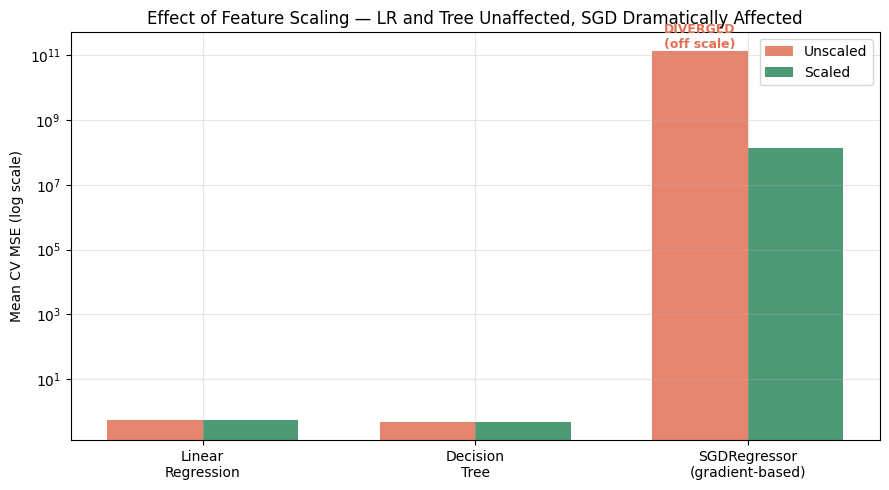

In [ ]:
# ── SGDRegressor: THIS is where scaling makes a dramatic difference ──
#
# SGDRegressor learns via gradient descent (Class: Gradient Descent & SGD).
# With unscaled features, 'Population' (range up to 35,000+) dominates the
# gradient completely compared to 'MedInc' (range 0-15) — the optimiser
# takes wildly uneven steps across dimensions and struggles to converge.

sgd_unscaled_cv = cv_mse(
    SGDRegressor(max_iter=1000, learning_rate='constant',
    eta0=0.001,
    tol=1e-4,
    random_state=42),
    X_train, y_train
) # USING ORGINAL TRAINING DATA HERE
sgd_scaled_cv = cv_mse(
    SGDRegressor(max_iter=1000, learning_rate='constant',
    eta0=0.001,
    tol=1e-4,
    random_state=42),
    X_train_scaled, y_train
) # USING SCALED TRAINING DATA HERE


model.fit(X_train_scaled, y_train)


def format_mse(value):
    # Unscaled SGD can literally diverge (MSE explodes to astronomical values).
    # Use scientific notation for huge numbers so the output stays readable.
    if value > 1e6:
        return f"{value:.3e}  <-- DIVERGED (astronomically large, PLS NOTE THIS IS not a typo)"
    return f"{value:.4f}"

print("SGDRegressor (Linear Regression trained by Gradient Descent)")
print(f"  Mean CV MSE (unscaled): {format_mse(sgd_unscaled_cv.mean())}")
print(f"  Mean CV MSE (scaled)  : {format_mse(sgd_scaled_cv.mean())}")
print()
if sgd_unscaled_cv.mean() > 1e6:
    print("  --> THIS is the dramatic difference. Without scaling, features like")
    print("      'Population' (range up to ~35,000) completely dominate the gradient")
    print("      compared to 'MedInc' (range 0-15). The optimiser takes huge, unstable")
    print("      steps and DIVERGES — the loss explodes instead of decreasing.")
    print("      With scaling, the exact same algorithm converges normally.")
else:
    ratio = sgd_unscaled_cv.mean() / max(sgd_scaled_cv.mean(), 1e-9)
    print(f"  Ratio (unscaled / scaled): {ratio:,.1f}x worse without scaling")
    print()
    print("  --> Gradient-based optimisers NEED scaled features to converge well.")
    print("      Without scaling, features with large natural ranges dominate the")
    print("      gradient, causing slow or unstable convergence.")

# Visual comparison across all three models.
# Cap the SGD-unscaled bar for PLOTTING only (it can be astronomically large
# if SGD diverged) -- the real printed number above is never altered.
PLOT_CAP = max(lin_unscaled_cv.mean(), tree_unscaled_cv.mean(), sgd_scaled_cv.mean()) * 1000

fig, ax = plt.subplots(figsize=(9, 5))
models = ['Linear\nRegression', 'Decision\nTree', 'SGDRegressor\n(gradient-based)']
unscaled_vals = [lin_unscaled_cv.mean(), tree_unscaled_cv.mean(), min(sgd_unscaled_cv.mean(), PLOT_CAP)]
scaled_vals   = [lin_scaled_cv.mean(), tree_scaled_cv.mean(), sgd_scaled_cv.mean()]

x_pos = np.arange(3)
w = 0.35
ax.bar(x_pos - w/2, unscaled_vals, w, label='Unscaled', color='#E17055', alpha=0.85)
ax.bar(x_pos + w/2, scaled_vals, w, label='Scaled', color='#2D8A5E', alpha=0.85)

if sgd_unscaled_cv.mean() > PLOT_CAP:
    ax.text(x_pos[2] - w/2, PLOT_CAP, 'DIVERGED\n(off scale)', ha='center', va='bottom',
            fontsize=9, color='#E17055', fontweight='bold')

ax.set_yscale('log')
ax.set_xticks(x_pos)
ax.set_xticklabels(models)
ax.set_ylabel('Mean CV MSE (log scale)')
ax.set_title('Effect of Feature Scaling — LR and Tree Unaffected, SGD Dramatically Affected')
ax.legend()
plt.tight_layout()
plt.show()


**NOTE**



1. eta0 = 0.001 → your initial/manual learning rate (α=0.001)
2. learning_rate ='constant' → keep the learning rate fixed at 0.001
3. max_iter=1000 → maximum number of passes/iterations
4. tol=1e-4 → stopping tolerance (stops training early if the optimization is no longer improving enough - the difference between old cost and new cost values)	​


**in SGD for Scaled data:**

though the scaling is done and so the dataset becomes better, but the chosen
SGD learning-rate/settings are still not necessarily appropriate for this dataset.

SGD may need a suitable learning rate, more iterations, and/or a learning-rate schedule.

## 9. Feature Selection

Remember: we deliberately injected `noise_1` and `noise_2` — pure random numbers — into this real dataset back in Section 1.

A good feature selection method should identify these as useless  features and discard them.


In [ ]:
# Select the top-8 features (out of 10 total: 8 real + 2 noise) using only the training data.
selector = SelectKBest(score_func=f_regression, k=8)
selector.fit(X_train, y_train)

selected_features = X_train.columns[selector.get_support()]
rejected_features = X_train.columns[~selector.get_support()]

print("Selected features:", list(selected_features))
print("Rejected features:", list(rejected_features))
print()

# Display all feature scores, sorted.
scores = pd.Series(selector.scores_, index=X_train.columns).sort_values(ascending=False)
print("Feature scores (higher = stronger real relationship with price):")
print(scores.round(2))
print()

if 'noise_1' in rejected_features and 'noise_2' in rejected_features:
    print("--> SUCCESS: SelectKBest correctly identified BOTH injected noise")
    print("    features as the least useful, and excluded them automatically.")
else:
    print("--> Note: check which features scored lowest above.")


Selected features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Rejected features: ['noise_1', 'noise_2']

Feature scores (higher = stronger real relationship with price):
MedInc        13964.81
AveRooms        390.27
Latitude        320.13
HouseAge        166.92
AveBedrms        34.91
Longitude        34.66
Population       10.44
AveOccup          7.11
noise_2           3.40
noise_1           0.13
dtype: float64

--> SUCCESS: SelectKBest correctly identified BOTH injected noise
    features as the least useful, and excluded them automatically.


Linear Regression
  Mean CV MSE (all 10 features, incl. noise): 0.5224
  Mean CV MSE (8 selected features)          : 0.5222

Decision Tree (max_depth=6)
  Mean CV MSE (all 10 features, incl. noise): 0.4845
  Mean CV MSE (8 selected features)          : 0.4849

--> Removing pure noise columns rarely hurts, and often helps slightly —
    the model no longer wastes its capacity trying to find patterns in randomness.


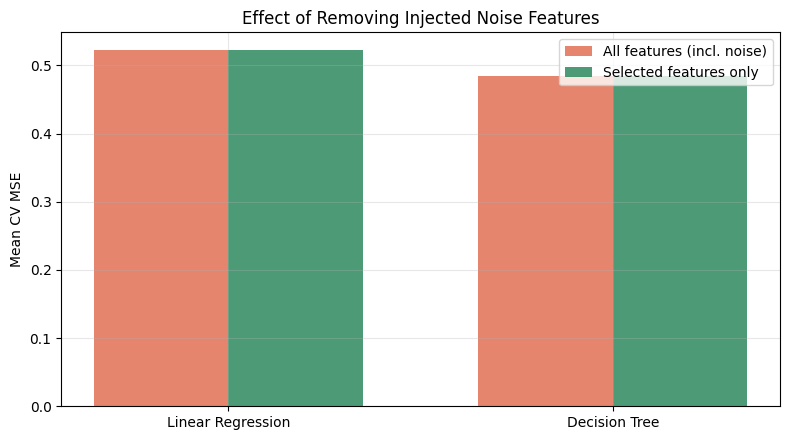

In [ ]:
# Compare model performance: ALL features (including noise) vs SELECTED features only.
X_train_sel = X_train[selected_features]
X_test_sel = X_test[selected_features]   # same selected columns, never re-fit on test

lin_all_cv = cv_mse(LinearRegression(), X_train, y_train)
lin_sel_cv = cv_mse(LinearRegression(), X_train_sel, y_train)

tree_all_cv = cv_mse(DecisionTreeRegressor(max_depth=6, random_state=42), X_train, y_train)
tree_sel_cv = cv_mse(DecisionTreeRegressor(max_depth=6, random_state=42), X_train_sel, y_train)

print("Linear Regression")
print(f"  Mean CV MSE (all 10 features, incl. noise): {lin_all_cv.mean():.4f}")
print(f"  Mean CV MSE (8 selected features)          : {lin_sel_cv.mean():.4f}")
print()
print("Decision Tree (max_depth=6)")
print(f"  Mean CV MSE (all 10 features, incl. noise): {tree_all_cv.mean():.4f}")
print(f"  Mean CV MSE (8 selected features)          : {tree_sel_cv.mean():.4f}")
print()
print("--> Removing pure noise columns rarely hurts, and often helps slightly —")
print("    the model no longer wastes its capacity trying to find patterns in randomness.")

# Visual
fig, ax = plt.subplots(figsize=(8, 4.5))
categories = ['Linear Regression', 'Decision Tree']
all_feat = [lin_all_cv.mean(), tree_all_cv.mean()]
sel_feat = [lin_sel_cv.mean(), tree_sel_cv.mean()]
x_pos = np.arange(2)
w = 0.35
ax.bar(x_pos - w/2, all_feat, w, label='All features (incl. noise)', color='#E17055', alpha=0.85)
ax.bar(x_pos + w/2, sel_feat, w, label='Selected features only', color='#2D8A5E', alpha=0.85)
ax.set_xticks(x_pos)
ax.set_xticklabels(categories)
ax.set_ylabel('Mean CV MSE')
ax.set_title('Effect of Removing Injected Noise Features')
ax.legend()
plt.tight_layout()
plt.show()


## 10. Cross-Validation — 5-Fold CV vs a Single "Standard" Split

There are two ways to estimate how well a model generalises:

1. **Standard split**: one train/validation split, evaluated once — this is what most beginners do
2. **5-Fold CV**: five different splits, averaged together, with a reported mean AND std

**The core problem with a standard single split:** in real practice, you only ever run it ONCE. Whatever MSE that one split happens to give you, you have **no way of knowing** whether you got lucky, unlucky, or a typical result — because you never see the alternative splits you *didn't* pick.

**What we demonstrate below:** we simulate what "luck" would have looked like, by repeating the standard split with 10 different random seeds. This reveals real variation that a beginner running it just once would never see. Cross-validation solves this properly — it doesn't rely on hoping your one split is representative; it evaluates on every part of the data and reports a mean **and** a spread (std) as standard output, using each data point for both training and validation exactly once.


STANDARD SINGLE SPLIT — Linear Regression, 10 different random seeds
[0.5001 0.5186 0.5226 0.5063 0.5252 0.5111 0.5193 0.5554 0.5    1.4573]

Mean  : 0.6116
Std   : 0.2823
Range : 0.5000 to 1.4573  (spread of 0.9572)

--> In real practice, you would run this ONCE with ONE seed (commonly the
    default, e.g. random_state=42) and report THAT number, with no idea
    whether it landed near the low end, the high end, or the middle of
    this range. That hidden uncertainty is the real problem.

5-FOLD CROSS-VALIDATION — Linear Regression, ONE run, ONE command
[0.4959 0.5045 0.5473 0.5181 0.546 ]

Mean : 0.5224
Std  : 0.0211

THE KEY DIFFERENCE
-----------------------------------------------------------------
Standard single split : gives you ONE number (0.5001 if seed=0),
                        with no built-in way to know how much it might
                        have varied with a different seed.
5-Fold CV              : gives you a MEAN (0.5224) AND a STD
                        (0.02

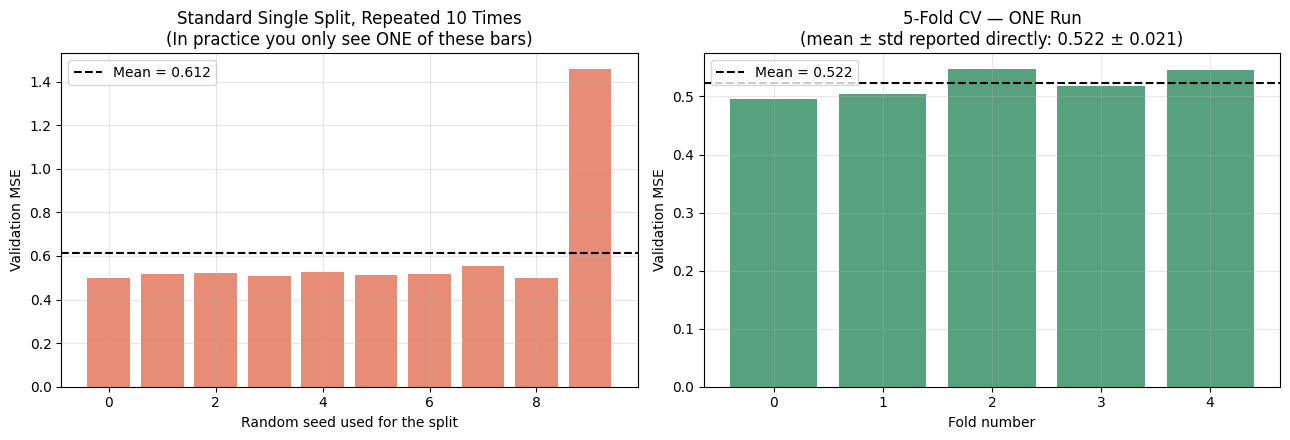

In [ ]:
# ── STANDARD SINGLE SPLIT, repeated with different random seeds ──
single_split_mses = []

for seed in range(10):
    Xs_tr, Xs_val, ys_tr, ys_val = train_test_split(
        X_train, y_train, test_size=0.2, random_state=seed
    )
    m = LinearRegression()
    m.fit(Xs_tr, ys_tr)
    mse_val = mean_squared_error(ys_val, m.predict(Xs_val))
    single_split_mses.append(mse_val)

single_split_mses = np.array(single_split_mses)

print("STANDARD SINGLE SPLIT — Linear Regression, 10 different random seeds")
print("=" * 65)
print(np.round(single_split_mses, 4))
print()
print(f"Mean  : {single_split_mses.mean():.4f}")
print(f"Std   : {single_split_mses.std():.4f}")
print(f"Range : {single_split_mses.min():.4f} to {single_split_mses.max():.4f}  "
      f"(spread of {single_split_mses.max() - single_split_mses.min():.4f})")
print()
print("--> In real practice, you would run this ONCE with ONE seed (commonly the")
print("    default, e.g. random_state=42) and report THAT number, with no idea")
print("    whether it landed near the low end, the high end, or the middle of")
print("    this range. That hidden uncertainty is the real problem.")
print()

# ── 5-FOLD CV, for comparison ──
cv_5fold = cv_mse(LinearRegression(), X_train, y_train)

print("5-FOLD CROSS-VALIDATION — Linear Regression, ONE run, ONE command")
print("=" * 65)
print(np.round(cv_5fold, 4))
print()
print(f"Mean : {cv_5fold.mean():.4f}")
print(f"Std  : {cv_5fold.std():.4f}")
print()

print("THE KEY DIFFERENCE")
print("-" * 65)
print(f"Standard single split : gives you ONE number ({single_split_mses[0]:.4f} if seed=0),")
print("                        with no built-in way to know how much it might")
print("                        have varied with a different seed.")
print(f"5-Fold CV              : gives you a MEAN ({cv_5fold.mean():.4f}) AND a STD")
print(f"                        ({cv_5fold.std():.4f}) in one principled procedure —")
print("                        every data point is used for both training and")
print("                        validation, and the spread is reported automatically.")
print()
print("--> This is why CV, not a single split, is the standard for model")
print("    selection and hyperparameter tuning: it reports its own uncertainty")
print("    as part of the result, instead of hiding it.")

# Visualise
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(range(10), single_split_mses, color='#E17055', alpha=0.8)
axes[0].axhline(single_split_mses.mean(), color='black', linestyle='--',
                 label=f'Mean = {single_split_mses.mean():.3f}')
axes[0].set_xlabel('Random seed used for the split')
axes[0].set_ylabel('Validation MSE')
axes[0].set_title('Standard Single Split, Repeated 10 Times\n(In practice you only see ONE of these bars)')
axes[0].legend()

axes[1].bar(range(5), cv_5fold, color='#2D8A5E', alpha=0.8)
axes[1].axhline(cv_5fold.mean(), color='black', linestyle='--',
                 label=f'Mean = {cv_5fold.mean():.3f}')
axes[1].set_xlabel('Fold number')
axes[1].set_ylabel('Validation MSE')
axes[1].set_title(f'5-Fold CV — ONE Run\n(mean ± std reported directly: {cv_5fold.mean():.3f} ± {cv_5fold.std():.3f})')
axes[1].legend()

plt.tight_layout()
plt.show()


## 11. Final Model Selection and Untouched Test Evaluation

Now we follow the proper workflow, end to end, on the real dataset.

We already selected the best Decision Tree depth using CV in Section 6 (`best_depth`).

1. Train the selected model on the **full training set**.
2. Use the final test set **once**.
3. Report **MSE, RMSE, and MAE** — plus a clear **Train vs CV vs Test** comparison table.

The test result must not be used to change the model after this point.


In [ ]:
# The best depth was selected earlier using CV on X_train only (Section 6).

final_tree = DecisionTreeRegressor(max_depth= best_depth, random_state=42)
final_tree.fit(X_train, y_train)
# we are using X_train here instead of X_train_sel or X_train_scaled,
# because we did'nt got any significant difference during our analysis
# if you get significant difference in performance in your dataset or model
# you can use the scaled or feature selected or both (check next section 11a)

final_linear = LinearRegression()
final_linear.fit(X_train, y_train)

# Final test evaluation: the FIRST time the final test set is used at all.
final_tree_pred = final_tree.predict(X_test)
final_linear_pred = final_linear.predict(X_test)

def evaluate(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    return mse, rmse, mae

tree_test_mse, tree_test_rmse, tree_test_mae = evaluate(y_test, final_tree_pred)
lin_test_mse, lin_test_rmse, lin_test_mae = evaluate(y_test, final_linear_pred)

print("=" * 60)
print(f"  FINAL TEST RESULTS  (test set used ONCE, here)")
print("=" * 60)
print()
print(f"Decision Tree (depth={best_depth}, selected via CV)")
print(f"  Test MSE  : {tree_test_mse:.4f}")
print(f"  Test RMSE : {tree_test_rmse:.4f}  ($100,000s)")
print(f"  Test MAE  : {tree_test_mae:.4f}  ($100,000s)")
print()
print(f"Linear Regression (baseline)")
print(f"  Test MSE  : {lin_test_mse:.4f}")
print(f"  Test RMSE : {lin_test_rmse:.4f}  ($100,000s)")
print(f"  Test MAE  : {lin_test_mae:.4f}  ($100,000s)")


  FINAL TEST RESULTS  (test set used ONCE, here)

Decision Tree (depth=9, selected via CV)
  Test MSE  : 0.4126
  Test RMSE : 0.6423  ($100,000s)
  Test MAE  : 0.4360  ($100,000s)

Linear Regression (baseline)
  Test MSE  : 0.5412
  Test RMSE : 0.7357  ($100,000s)
  Test MAE  : 0.5297  ($100,000s)


TRAIN vs CV vs TEST — THE CLEAREST COMPARISON IN THIS NOTEBOOK
                  Model  Train MSE  CV MSE (mean)  CV MSE (std)  Test MSE  Test RMSE  Test MAE
      Linear Regression     0.5205         0.5224        0.0211    0.5412     0.7357    0.5297
Decision Tree (depth=9)     0.2717         0.4381        0.0097    0.4126     0.6423    0.4360

Read this left to right for each model:
  Train MSE   : always the most OPTIMISTIC number (model has seen this data)
  CV MSE      : an HONEST estimate, computed without touching the test set
  Test MSE    : the FINAL, independent confirmation — computed only once

Notice how close CV MSE and Test MSE are to each other, and how both are
higher than Train MSE — this is expected and healthy. If Test MSE were wildly
different from CV MSE, that would be a red flag for something going wrong
(e.g. leakage, or a test set that isn't representative).


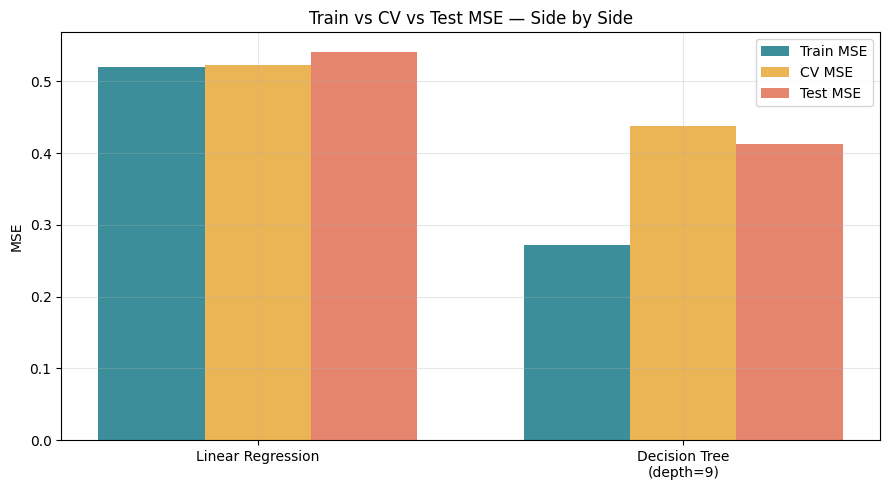

In [ ]:
# ── THE HEADLINE COMPARISON: Train vs CV vs Test, side by side ──
#
# This table is the clearest possible illustration of why we need all three.

tree_train_mse = mean_squared_error(y_train, final_tree.predict(X_train))
tree_cv_mse_final = cv_mse(DecisionTreeRegressor(max_depth=best_depth, random_state=42), X_train, y_train)

lin_train_mse = mean_squared_error(y_train, final_linear.predict(X_train))
lin_cv_mse_final = cv_mse(LinearRegression(), X_train, y_train)

comparison = pd.DataFrame({
    'Model': ['Linear Regression', f'Decision Tree (depth={best_depth})'],
    'Train MSE':  [lin_train_mse, tree_train_mse],
    'CV MSE (mean)': [lin_cv_mse_final.mean(), tree_cv_mse_final.mean()],
    'CV MSE (std)':  [lin_cv_mse_final.std(), tree_cv_mse_final.std()],
    'Test MSE':   [lin_test_mse, tree_test_mse],
    'Test RMSE':  [lin_test_rmse, tree_test_rmse],
    'Test MAE':   [lin_test_mae, tree_test_mae],
})

print("TRAIN vs CV vs TEST — THE CLEAREST COMPARISON IN THIS NOTEBOOK")
print("=" * 90)
print(comparison.round(4).to_string(index=False))
print()
print("Read this left to right for each model:")
print("  Train MSE   : always the most OPTIMISTIC number (model has seen this data)")
print("  CV MSE      : an HONEST estimate, computed without touching the test set")
print("  Test MSE    : the FINAL, independent confirmation — computed only once")
print()


print("Notice how close CV MSE and Test MSE are to each other, and how both are")
print("higher than Train MSE — this is expected and healthy. If Test MSE were wildly")
print("different from CV MSE, that would be a red flag for something going wrong")
print("(e.g. leakage, or a test set that isn't representative).")

# Visual
fig, ax = plt.subplots(figsize=(9, 5))
x_labels = ['Linear Regression', f'Decision Tree\n(depth={best_depth})']
train_vals = comparison['Train MSE'].values
cv_vals = comparison['CV MSE (mean)'].values
test_vals = comparison['Test MSE'].values

x_pos = np.arange(2)
w = 0.25
ax.bar(x_pos - w, train_vals, w, label='Train MSE', color='#1A7A8A', alpha=0.85)
ax.bar(x_pos,     cv_vals,    w, label='CV MSE',    color='#E8A838', alpha=0.85)
ax.bar(x_pos + w, test_vals,  w, label='Test MSE',  color='#E17055', alpha=0.85)
ax.set_xticks(x_pos)
ax.set_xticklabels(x_labels)
ax.set_ylabel('MSE')
ax.set_title('Train vs CV vs Test MSE — Side by Side')
ax.legend()
plt.tight_layout()
plt.show()


### 11a. Confirming the Scaling and Feature Selection Findings — On the Test Set

Sections 8 and 9 showed, using CV on training data only, that scaling and feature selection barely moved the needle for Linear Regression and Decision Trees. We can now **confirm** that finding on the untouched test set — the strongest possible evidence, since it was never involved in reaching that conclusion.

In [ ]:
# Does scaling change the final Linear Regression test result?
final_linear_scaled = LinearRegression()
final_linear_scaled.fit(X_train_scaled, y_train)
lin_scaled_test_mse = mean_squared_error(y_test, final_linear_scaled.predict(X_test_scaled))

# Does feature selection change the final Decision Tree test result?
final_tree_sel = DecisionTreeRegressor(max_depth=best_depth, random_state=42)
final_tree_sel.fit(X_train_sel, y_train)
tree_sel_test_mse = mean_squared_error(y_test, final_tree_sel.predict(X_test_sel))

print("CONFIRMING SECTION 8 (SCALING) ON THE TEST SET")
print("-" * 60)
print(f"  Linear Regression, unscaled features : Test MSE = {lin_test_mse:.4f}")
print(f"  Linear Regression, scaled features   : Test MSE = {lin_scaled_test_mse:.4f}")
print(f"  Difference: {abs(lin_test_mse - lin_scaled_test_mse):.6f}")
print()

print("CONFIRMING SECTION 9 (FEATURE SELECTION) ON THE TEST SET")
print("-" * 60)
print(f"  Decision Tree, all features (incl. noise) : Test MSE = {tree_test_mse:.4f}")
print(f"  Decision Tree, selected features only     : Test MSE = {tree_sel_test_mse:.4f}")
print(f"  Difference: {abs(tree_test_mse - tree_sel_test_mse):.6f}")
print()

print("--> Both differences are small, confirming on genuinely unseen data what")
print("    CV already told us: scaling and feature selection do not meaningfully")
print("    change these two model types. This is why the final models trained")
print("    above use the plain, unscaled, full feature set — simpler, with no")
print("    measurable cost. This conclusion is specific to Linear Regression and Decision Trees")

CONFIRMING SECTION 8 (SCALING) ON THE TEST SET
------------------------------------------------------------
  Linear Regression, unscaled features : Test MSE = 0.5412
  Linear Regression, scaled features   : Test MSE = 0.5412
  Difference: 0.000000

CONFIRMING SECTION 9 (FEATURE SELECTION) ON THE TEST SET
------------------------------------------------------------
  Decision Tree, all features (incl. noise) : Test MSE = 0.4126
  Decision Tree, selected features only     : Test MSE = 0.4084
  Difference: 0.004144

--> Both differences are small, confirming on genuinely unseen data what
    CV already told us: scaling and feature selection do not meaningfully
    change these two model types. This is why the final models trained
    above use the plain, unscaled, full feature set — simpler, with no
    measurable cost. This conclusion is specific to Linear Regression and Decision Trees


## 12. Key Takeaways

| Concept | What we saw on REAL data |
|---|---|
| **Baseline Models** | Linear Regression and an unrestricted Decision Tree already showed a Train-vs-CV gap — the tree's near-zero training error hinted at overfitting before we even studied it directly. |
| **Underfitting** | A single weak feature (`AveRooms` alone) or a depth-1 tree gave high error on BOTH training and CV — the model was too simple to capture real housing-price patterns. |
| **Overfitting** | An unrestricted Decision Tree achieved near-zero training error but a much higher CV error — a large Train/CV gap is the signature of overfitting. |
| **Bias–Variance Tradeoff** | Sweeping tree depth 1→25 produced the classic U-shaped CV curve: high error on both ends, with one clear minimum in between — selected using CV, never the test set. |
| **Data Leakage** | Scaling before splitting, and using a target-derived feature, both contaminate evaluation — the target-derived feature made MSE look absurdly better than reality. |
| **Feature Scaling** | Linear Regression and Decision Trees were virtually unaffected by scaling — but `SGDRegressor` (gradient-based) was dramatically affected, confirming scaling matters specifically for gradient-based optimisers. |
| **Feature Selection** | `SelectKBest` correctly identified and discarded the two deliberately injected noise columns, based purely on the training data. |
| **Cross-Validation** | A single "standard" split gives exactly one number, with its reliability hidden — repeating it with 10 seeds revealed real variation a beginner running it once would never see. 5-Fold CV reports a mean **and** a std in one principled procedure, making that uncertainty visible by default. |
| **Final Test Set** | Used only once, at the very end, after every decision was already made using training data and CV. Test MSE closely matched CV MSE — confirming the evaluation pipeline was honest. |

### The complete workflow

```
Real Data
   → Train/Test Split (test set locked)
   → Training + Cross-Validation
       (underfitting / overfitting / bias-variance / scaling / feature selection)
   → Model Selection (using CV only)
   → Retrain on Full Training Set
   → Final Test Evaluation (ONCE) — report MSE, RMSE, MAE
```

> **Golden rule:** Never use the final test result to choose the model, hyperparameters, features, preprocessing, or any other training decision. Every comparison in this notebook — underfitting, overfitting, scaling, feature selection, CV stability — was made using training data and cross-validation alone. The test set was touched exactly once, in Section 11.
